<a href="https://colab.research.google.com/github/Bhuvan152/cortical-forward-model-data-efficiency/blob/main/cortical_learning_curve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/jgranley/deep_neural_shaping.git
%cd deep_neural_shaping
!ls -la

Cloning into 'deep_neural_shaping'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 57 (delta 0), reused 7 (delta 0), pack-reused 46 (from 1)
Receiving objects: 100% (57/57), 57.82 MiB | 20.55 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/deep_neural_shaping
total 24912
drwxr-xr-x 4 root root     4096 Oct 29 00:07 .
drwxr-xr-x 1 root root     4096 Oct 29 00:07 ..
drwxr-xr-x 4 root root     4096 Oct 29 00:07 Data_publish_folder
-rw-r--r-- 1 root root 25480484 Oct 29 00:07 Data_publish_folder.zip
drwxr-xr-x 8 root root     4096 Oct 29 00:07 .git
-rw-r--r-- 1 root root     3443 Oct 29 00:07 .gitignore
-rw-r--r-- 1 root root     1500 Oct 29 00:07 LICENSE
-rw-r--r-- 1 root root      215 Oct 29 00:07 README.md


In [2]:
!find . -maxdepth 3 -not -path "./.git*" | head -100
print("=" * 60)
!du -sh * 2>/dev/null
print("=" * 60)
!cat README.md

.
./Data_publish_folder
./Data_publish_folder/Data
./Data_publish_folder/Data/df_results.pkl
./Data_publish_folder/Data/spike_mean.npy
./Data_publish_folder/Data/perception_per_day_metrics.csv
./Data_publish_folder/Data/binary_perception_results.csv
./Data_publish_folder/Data/pipfreeze.txt
./Data_publish_folder/Data/perception_overall_metrics.csv
./Data_publish_folder/Data/example_extract_activity.npy
./Data_publish_folder/Data/stim_variability.npy
./Data_publish_folder/Data/random_structured_examples.npy
./Data_publish_folder/requirements.txt
./Data_publish_folder/Dataset_description.docx
./Data_publish_folder/Code
./Data_publish_folder/Code/Fig2_supplementary.ipynb
./Data_publish_folder/Code/Fig3-5.ipynb
./Data_publish_folder/Code/src
./Data_publish_folder/Code/perception_figure.py
./README.md
./Data_publish_folder.zip
./LICENSE
64M	Data_publish_folder
25M	Data_publish_folder.zip
4.0K	LICENSE
4.0K	README.md
# Code and data supporting "Deep Learning–Based Control of Electrically Evoke

In [3]:
!find . -not -path "./.git*" \( -name "*.npy" -o -name "*.npz" -o -name "*.pkl" -o -name "*.pickle" -o -name "*.h5" -o -name "*.hdf5" -o -name "*.mat" -o -name "*.csv" -o -name "*.parquet" \) | head -50

./Data_publish_folder/Data/df_results.pkl
./Data_publish_folder/Data/spike_mean.npy
./Data_publish_folder/Data/perception_per_day_metrics.csv
./Data_publish_folder/Data/binary_perception_results.csv
./Data_publish_folder/Data/perception_overall_metrics.csv
./Data_publish_folder/Data/example_extract_activity.npy
./Data_publish_folder/Data/stim_variability.npy
./Data_publish_folder/Data/random_structured_examples.npy


In [4]:
# 1. Read the dataset description
!pip install -q python-docx
from docx import Document
doc = Document("Data_publish_folder/Dataset_description.docx")
for p in doc.paragraphs:
    if p.text.strip():
        print(p.text)
for t in doc.tables:
    for row in t.rows:
        print(" | ".join(c.text.strip() for c in row.cells))

DATASET DESCRIPTION
All the methods and the description on how the data of this dataset were acquired or processed can be found in the related publication.
This folder contains a Code subfolder with two notebooks and src code to reproduce the main figures from the text, and a Data folder with the data from the experiments necessary to run the notebooks.
Data organization
The main data with the results of the in vivo neural shaping experiment is stored in Data/df_results.pkl, and can be loaded into a dataframe using pandas. The dataframe has columns describing the stimulation pattern delivered to the 96 electrodes (‘stimulation'), the dMUAe resulting from stimulation ('diff_activity'), the target that the stimulation synthesis method was trying to reproduce ('target_response'), the name of the stimulation synthesis method ('name'), in addition to many other columns. See Fig3-5.ipynb for more examples on how to work with this dataframe.
There are also a number of additional files. These 

In [5]:
# 2. Peek inside each data file
import numpy as np, pandas as pd, os

base = "Data_publish_folder/Data/"
for f in sorted(os.listdir(base)):
    path = base + f
    print("=" * 60, "\n", f, f"({os.path.getsize(path)/1e6:.1f} MB)")
    try:
        if f.endswith(".npy"):
            arr = np.load(path, allow_pickle=True)
            print("  shape:", arr.shape, "dtype:", arr.dtype)
            if arr.dtype == object and arr.shape == ():
                obj = arr.item()
                print("  object type:", type(obj))
                if isinstance(obj, dict):
                    for k, v in obj.items():
                        print(f"   key '{k}':", getattr(v, "shape", type(v)))
        elif f.endswith(".pkl"):
            df = pd.read_pickle(path)
            print("  type:", type(df))
            if isinstance(df, pd.DataFrame):
                print("  shape:", df.shape)
                print("  columns:", list(df.columns)[:40])
                print(df.head(3))
            elif isinstance(df, dict):
                for k, v in df.items():
                    print(f"   key '{k}':", getattr(v, "shape", type(v)))
        elif f.endswith(".csv"):
            df = pd.read_csv(path)
            print("  shape:", df.shape, "columns:", list(df.columns)[:20])
    except Exception as e:
        print("  could not open:", type(e).__name__, e)

print("=" * 60)
!ls -la Data_publish_folder/Code/src

 binary_perception_results.csv (0.8 MB)
  shape: (6625, 10) columns: ['model', 'predictors', 'accuracy', 'f1', 'day', 'time_slice', 'window_size', 'window_stride', 'agg', 'cv']
 df_results.pkl (7.3 MB)
  type: <class 'pandas.core.frame.DataFrame'>
  shape: (1645, 11)
  columns: ['stimulation', 'diff_activity', 'target_response', 'name', 'idx', 'target_id', 'answer', 'before_activity', 'after_activity', 'OOD', 'simulated_response']
                                         stimulation  \
0  [0.0, 0.0, 7.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0, ...   
1  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
2  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   

                                       diff_activity  \
0  [-2.3023421107621482, 0.035354048248351866, -0...   
1  [1.3899422077658738, -0.09306597352697654, -0....   
2  [-0.25363684657590024, -0.24696416274335053, -...   

                                     target_response             name  idx  \
0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

In [6]:
import numpy as np, pandas as pd

df = pd.read_pickle("Data_publish_folder/Data/df_results.pkl")
S   = np.stack(df.stimulation.values).astype(float)        # stimulation (trials, 96)
Y   = np.stack(df.diff_activity.values).astype(float)      # measured response (trials, 96)
B   = np.stack(df.before_activity.values).astype(float)    # pre-stimulation activity
SIM = np.stack(df.simulated_response.values).astype(float) # paper's forward-model prediction
print("Shapes:", S.shape, Y.shape, B.shape, SIM.shape)

print("\nTrials per method:\n", df.name.value_counts())
print("\nOut-of-distribution (synthetic) targets:\n", df.OOD.value_counts())

# Identify repeated stimulation patterns
keys = pd.Series([tuple(np.round(s, 3)) for s in S])
df["stim_key"] = pd.factorize(keys)[0]
print("\nUnique stimulation patterns:", df.stim_key.nunique())
print("Repeats per pattern:\n", df.stim_key.value_counts().value_counts().sort_index())
print("Zero-stimulation trials:", int((S.sum(axis=1) == 0).sum()))

# Responsive channels (the paper kept channels with response variance > 0.2)
valid = Y.var(axis=0) > 0.2
print("\nResponsive channels (variance > 0.2):", int(valid.sum()), "of 96")
print("Stimulation range:", S.min(), "to", S.max())

Shapes: (1645, 96) (1645, 96) (1645, 96) (1645, 96)

Trials per method:
 name
Generator 2             175
STA                     175
Naive                   175
Grad                    175
Linear                  175
Generator 3             160
Generator 3 Rescaled    160
Grad 2                  160
Grad Max Scaled          75
Generator 1              75
Grad Max                 75
Previous                 65
Name: count, dtype: int64

Out-of-distribution (synthetic) targets:
 OOD
True     840
False    805
Name: count, dtype: int64

Unique stimulation patterns: 370
Repeats per pattern:
 count
4     243
5     125
8       1
40      1
Name: count, dtype: int64
Zero-stimulation trials: 40

Responsive channels (variance > 0.2): 47 of 96
Stimulation range: 0.0 to 50.0


In [7]:
from sklearn.metrics import r2_score

def r2_channels(y_true, y_pred, ch=valid):
    """R² computed per channel, then averaged over responsive channels (as in the paper)."""
    return r2_score(y_true[:, ch], y_pred[:, ch], multioutput="raw_values").mean()

# 1. How well does the paper's forward model predict these in vivo responses?
print(f"Paper's forward model R² on all trials: {r2_channels(Y, SIM):.3f}")

# 2. Noise ceiling: predict each trial by the mean of the OTHER repeats of the same pattern
loo = np.full_like(Y, np.nan)
for k, grp in df.groupby("stim_key").groups.items():
    idx = np.array(list(grp))
    if len(idx) < 2:
        continue
    total = Y[idx].sum(axis=0)
    for i in idx:
        loo[i] = (total - Y[i]) / (len(idx) - 1)
has_rep = ~np.isnan(loo[:, 0])
print(f"Trials with repeats: {has_rep.sum()}")
print(f"Noise ceiling R² (repeat-based): {r2_channels(Y[has_rep], loo[has_rep]):.3f}")
print(f"Paper's model R² on the same trials: {r2_channels(Y[has_rep], SIM[has_rep]):.3f}")

Paper's forward model R² on all trials: 0.200
Trials with repeats: 1645
Noise ceiling R² (repeat-based): 0.250
Paper's model R² on the same trials: 0.200


In [9]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.neural_network import MLPRegressor
import warnings; warnings.filterwarnings("ignore")

keep = S.sum(axis=1) > 0
patterns = np.unique(df.stim_key[keep])
rng = np.random.default_rng(0)

sizes = [10, 20, 40, 80, 160, None]
N_SPLITS, N_DRAWS = 5, 3
models = ["Mean response", "Ridge (linear)", "MLP (nonlinear)"]
results = {m: {s: [] for s in sizes} for m in models}
n_trials = {s: [] for s in sizes}
ref_paper, ref_ceiling = [], []

def fit_ridge_grouped(X, y, groups):
    """Choose ridge strength with CV grouped by stimulation pattern (no leakage across repeats)."""
    search = GridSearchCV(Ridge(), {"alpha": np.logspace(-2, 4, 13)},
                          cv=GroupKFold(n_splits=5), scoring="neg_mean_squared_error")
    search.fit(X, y, groups=groups)
    return search.best_estimator_

for split in range(N_SPLITS):
    perm = rng.permutation(patterns)
    n_test = len(patterns) // 5
    test_p, train_pool = perm[:n_test], perm[n_test:]
    te = np.where(keep & df.stim_key.isin(test_p))[0]

    ref_paper.append(r2_channels(Y[te], SIM[te]))
    ok = te[has_rep[te]]
    ref_ceiling.append(r2_channels(Y[ok], loo[ok]))

    for size in sizes:
        n = len(train_pool) if size is None else size
        for d in range(1 if size is None else N_DRAWS):
            tp = rng.choice(train_pool, n, replace=False)
            tr = np.where(keep & df.stim_key.isin(tp))[0]
            n_trials[size].append(len(tr))
            Xtr, Xte = S[tr] / 50.0, S[te] / 50.0

            results["Mean response"][size].append(
                r2_channels(Y[te], np.tile(Y[tr].mean(axis=0), (len(te), 1))))

            ridge = fit_ridge_grouped(Xtr, Y[tr], df.stim_key.values[tr])
            results["Ridge (linear)"][size].append(r2_channels(Y[te], ridge.predict(Xte)))

            mlp = MLPRegressor(hidden_layer_sizes=(128, 128), alpha=1e-2, max_iter=800,
                               early_stopping=len(tr) >= 300, random_state=d)
            mlp.fit(Xtr, Y[tr])
            results["MLP (nonlinear)"][size].append(r2_channels(Y[te], mlp.predict(Xte)))
    print(f"Split {split+1}/{N_SPLITS} done")

print(f"\nPaper's forward model (trained on months of data): R² = {np.mean(ref_paper):.3f}")
print(f"Noise ceiling (repeat-based):                       R² = {np.mean(ref_ceiling):.3f}\n")
for size in sizes:
    line = f"{np.mean(n_trials[size]):6.0f} training trials -> "
    line += ", ".join(f"{m}: {np.mean(results[m][size]):.3f}" for m in models)
    print(line)

Split 1/5 done
Split 2/5 done
Split 3/5 done
Split 4/5 done
Split 5/5 done

Paper's forward model (trained on months of data): R² = 0.168
Noise ceiling (repeat-based):                       R² = 0.202

    44 training trials -> Mean response: -0.084, Ridge (linear): -0.062, MLP (nonlinear): -0.122
    88 training trials -> Mean response: -0.045, Ridge (linear): 0.006, MLP (nonlinear): -0.096
   176 training trials -> Mean response: -0.025, Ridge (linear): 0.049, MLP (nonlinear): -0.063
   349 training trials -> Mean response: -0.017, Ridge (linear): 0.087, MLP (nonlinear): 0.039
   696 training trials -> Mean response: -0.014, Ridge (linear): 0.126, MLP (nonlinear): 0.101
  1290 training trials -> Mean response: -0.011, Ridge (linear): 0.140, MLP (nonlinear): 0.127


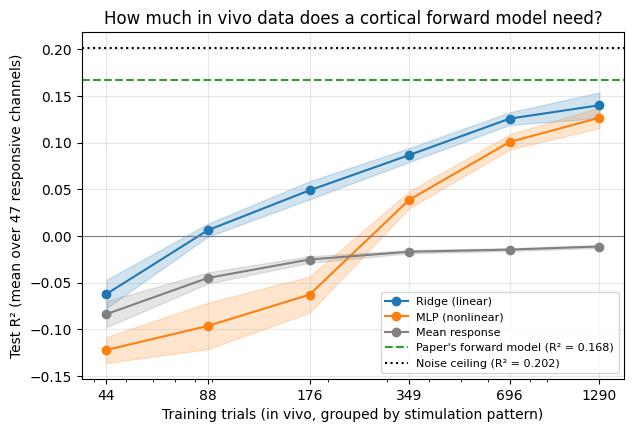

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.pyplot as plt

x = [np.mean(n_trials[s]) for s in sizes]
plt.figure(figsize=(7, 4.5))
for m, color in zip(["Ridge (linear)", "MLP (nonlinear)", "Mean response"], ["C0", "C1", "gray"]):
    means = np.array([np.mean(results[m][s]) for s in sizes])
    sems = np.array([np.std(results[m][s]) / np.sqrt(len(results[m][s])) for s in sizes])
    plt.plot(x, means, marker="o", color=color, label=m)
    plt.fill_between(x, means - sems, means + sems, color=color, alpha=0.2)

plt.axhline(np.mean(ref_paper), color="C2", linestyle="--",
            label=f"Paper's forward model (R² = {np.mean(ref_paper):.3f})")
plt.axhline(np.mean(ref_ceiling), color="black", linestyle=":",
            label=f"Noise ceiling (R² = {np.mean(ref_ceiling):.3f})")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xscale("log")
plt.xticks(x, [f"{v:.0f}" for v in x])
plt.xlabel("Training trials (in vivo, grouped by stimulation pattern)")
plt.ylabel("Test R² (mean over 47 responsive channels)")
plt.title("How much in vivo data does a cortical forward model need?")
plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.3)
plt.savefig("learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("learning_curve.png")